# Genetic Risk Prediction: Expression PRS (NBK 3)

This notebook focuses on building a **polygenic predictor of a gene's own expression** from its cis-eQTLs. For each gene of interest, we can take the cis-eQTL effect sizes discovered, combine them into a single **polygenic risk score (PRS)**, and evaluate how well that score explains gene expression in held-out individuals.

We can first restrict to a small, deliberately chosen set of genes and compare each one's PRS performance to a null model with effect sizes permuted to confirm the signal is real rather than statistical noise.

To begin, the following prerequisites are required to run this notebook without any errors:

- NBK 1 (`data_wrangling.ipynb`) and NBK 2 (`cis_eqtl_discovery.ipynb`) reviewed, as this NBK builds directly on both.
- `data/genotype/LDREF/` populated with the 1000G EUR PLINK filesets (`1000G.EUR.{1..22}.{bed,bim,fam}`)
- `data/phenotype/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt.gz` (Geuvadis expression matrix)
- `data/annotation/gene_annot.txt.gz` (gene annotation table)
- Python environment with `numpy`, `pandas`, `scipy`, `matplotlib`, `bed-reader` installed (see `requirements.txt`)
- `helpers.py` present in the same directory as this notebook

---

### Import statements

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers

---

### Loading inputs from NBK 1

Specifically, we need the **Geuvadis expression matrix**, the **1000 Genomes EUR genotypes for Chromosome 22**, the **gene annotation**, and the **shared cohort** of individuals present in both genotype and expression datasets.


In [17]:
expression_df = helpers.read_expression()
metadata_columns = ["TargetID", "Gene_Symbol", "Chr", "Coord"]
sample_ids = [column for column in expression_df if column not in metadata_columns]
annotation_df = helpers.read_gene_annotation()
genotype_matrix = helpers.read_genotypes(helpers.ldref_prefix(22))[0]
iids = helpers.read_genotypes(helpers.ldref_prefix(22))[1]
bim_df = helpers.read_genotypes(helpers.ldref_prefix(22))[2]
shared_individuals = sorted(set(str(i) for i in iids) & set(sample_ids))

print(f"Gene expression matrix: {expression_df.shape}")
print(f"Chromosome 22 genotypes: {genotype_matrix.shape[0]} individuals x {genotype_matrix.shape[1]} SNPs")
print(f"Shared cohort: {len(shared_individuals)} individuals")

Gene expression matrix: (23722, 466)
Chromosome 22 genotypes: 489 individuals x 17489 SNPs
Shared cohort: 344 individuals


---

### Understanding Expression PRS from cis-eQTLs

A **Polygenic Risk Score (PRS)** combines the effect sizes of many SNPs into a single numerical predictor. The classical use is predicting disease risk from GWAS summary statistics. Here we flip the target, as instead of predicting a disease, we predict a gene's **expression level** using the discovered cis-eQTLs. This is an **expression PRS**:

$$\text{PRS}_i = \sum_{k \in \text{selected SNPs}} \beta_k \cdot \text{genotype}_{i,k}$$

where $\beta_k$ is the effect size of SNP $k$ (from the cis-eQTL regression) and $\text{genotype}_{i,k}$ is person $i$'s allele dosage at SNP $k$ (0 / 1 / 2). The sum runs over SNPs that survive **linkage disequilibrium clumping + p-value thresholding**: clumping removes SNPs in strong linkage with a stronger lead SNP (i.e. we choose only one SNP to be the index SNP for the signal as the others are correlated by proximity), and thresholding keeps only SNPs below some p-value cutoff.

To evaluate PRS performance fairly, we can use a **60 / 30 / 10 train / validation / test split** of the 344 shared individuals:

1. **Train (60%)** — we can run the cis-eQTL regression here to obtain β per SNP
2. **Validation (30%)** — we can try several p-value cutoffs and pick the one that maximises R² between PRS and true expression
3. **Test (10%)** — we can report final R² using the chosen cutoff as this split was never seen during training or tuning

That said, to confirm any R² we see is **real signal** rather than noise, we can also fit a **null model**, which is essentially the same pipeline, but with effect sizes **permuted** so the SNP–expression relationship is destroyed. If the real R² clearly beats the null R², the signal is genuine.

---

### Selecting test genes

Rather than picking genes by hand, we can use a data-driven approach: the Chromosome 22 genes with the **strongest cis-eQTL signal** from previous analysis. These are the genes where cis-regulatory variation is most clearly detectable and serve as the natural candidates for expression PRS to work. We can also continue to include **COMT** (even if it's not in the top set) for continuity with the previous single-gene analysis.

In [18]:
chr22_eqtl_results = pd.read_csv("../output/eqtl_results/chr22_eqtl_results.csv")
gene_min_pval = chr22_eqtl_results.groupby("gene")["pval"].min().sort_values()
print(f"Total Chromosome 22 genes with at least one cis-eQTL: {len(gene_min_pval)}")

TOP_N = 10
test_genes = gene_min_pval.head(TOP_N).index.tolist()

comt_ensembl = "ENSG00000093010"
if comt_ensembl not in test_genes:
    test_genes.append(comt_ensembl)
    print(f"Adding COMT ({comt_ensembl}) for continuity in analysis.")

print(f"\nFinal gene set: {len(test_genes)} genes")
for g in test_genes:
    print(f"{g} (min cis-eQTL p = {gene_min_pval[g]:.2e})")

Total Chromosome 22 genes with at least one cis-eQTL: 344
Adding COMT (ENSG00000093010) for continuity in analysis.

Final gene set: 11 genes
ENSG00000100376 (min cis-eQTL p = 3.26e-87)
ENSG00000100321 (min cis-eQTL p = 6.33e-59)
ENSG00000167074 (min cis-eQTL p = 4.84e-26)
ENSG00000100299 (min cis-eQTL p = 1.02e-25)
ENSG00000183172 (min cis-eQTL p = 5.28e-17)
ENSG00000100417 (min cis-eQTL p = 6.61e-17)
ENSG00000100147 (min cis-eQTL p = 5.00e-16)
ENSG00000100368 (min cis-eQTL p = 9.37e-15)
ENSG00000100266 (min cis-eQTL p = 1.79e-14)
ENSG00000100336 (min cis-eQTL p = 2.34e-14)
ENSG00000093010 (min cis-eQTL p = 9.32e-05)


As such, we select 11 genes of interest for our analysis.

---

### Aligning genotype rows to the shared cohort

Replicating prior steps, we can restrict the Chromosome 22 genotype matrix to only the 344 shared individuals, so rows match the expression vectors that we pull per gene.

In [19]:
row_index = {iid: i for i, iid in enumerate(iids)}
shared_rows = [row_index[iid] for iid in shared_individuals]
aligned_genotype = genotype_matrix[shared_rows, :]
print(f"Aligned genotype matrix: {aligned_genotype.shape}")

Aligned genotype matrix: (344, 17489)


---

### Running expression PRS cross-validation for each gene

For each selected gene, we can run the full pipeline via `helpers.cross_validate_gene`: 60/30/10 split → cis-eQTL regression on train → LD clump → tune p-value threshold on validation → final test R² → null comparison.


In [20]:
cv_results = []
for ensembl in test_genes:
    gene_row = annotation_df[annotation_df["SYM"] == ensembl]
    if gene_row.empty:
        continue
    gene_row = gene_row.iloc[0]

    expression_row = expression_df[expression_df["TargetID"].str.startswith(ensembl)]
    if expression_row.empty:
        continue
    expression_vec = expression_row.iloc[0][shared_individuals].to_numpy(dtype=float)
    if np.all(np.isnan(expression_vec)):
        continue

    cv = helpers.cross_validate_gene(aligned_genotype, bim_df, expression_vec, start=int(gene_row["START"]), stop=int(gene_row["STOP"]), seed=42)
    if cv is None:
        continue

    cv_results.append({"gene": ensembl, "symbol": gene_row["ID"], **cv})

cv_df = pd.DataFrame(cv_results).sort_values("test_r2", ascending=False).reset_index(drop=True)
cv_df

,gene,symbol,n_cis,n_clumped,best_threshold,val_r2,test_r2,null_test_r2
0,ENSG00000100376,FAM118A,698,103,0.001,0.565085,0.581173,0.068325
1,ENSG00000100321,SYNGR1,405,47,0.001,0.541405,0.529248,0.454706
2,ENSG00000100299,ARSA,401,50,0.001,0.421451,0.342394,0.474616
3,ENSG00000100336,APOL4,484,77,0.001,0.207221,0.300733,0.300733
4,ENSG00000100417,PMM1,278,23,0.500,0.224814,0.288485,0.222810
5,ENSG00000100147,CCDC134,283,21,0.050,0.184012,0.172407,0.052822
6,ENSG00000100368,CSF2RB,664,87,0.001,0.175632,0.128543,0.059226
7,ENSG00000167074,TEF,299,24,0.200,0.342166,0.122096,0.279460
8,ENSG00000183172,SMDT1,309,22,0.001,0.187206,0.026189,0.026189
9,ENSG00000093010,COMT,509,72,0.050,0.014709,0.011515,0.019260


In this DataFrame, each row is one gene's expression PRS result: number of cis-SNPs tested, number surviving clumping, the p-value threshold chosen on validation, the final test R² (performance on unseen data), and the null-model test R² (what random effect sizes would give). The gap between `test_r2` and `null_test_r2` is the gene's real cis-regulatory signal.

---

### Visualising PRS vs null across genes

We can now plot side-by-side bars per gene: real PRS test R² vs null test R². Genes where the blue bar clearly exceeds the grey bar show real, meaningful expression prediction from cis-genotypes. Genes where the two match (or null ≥ real) indicate the method isn't capturing real signal for those genes. This is expected for weakly cis-regulated genes.

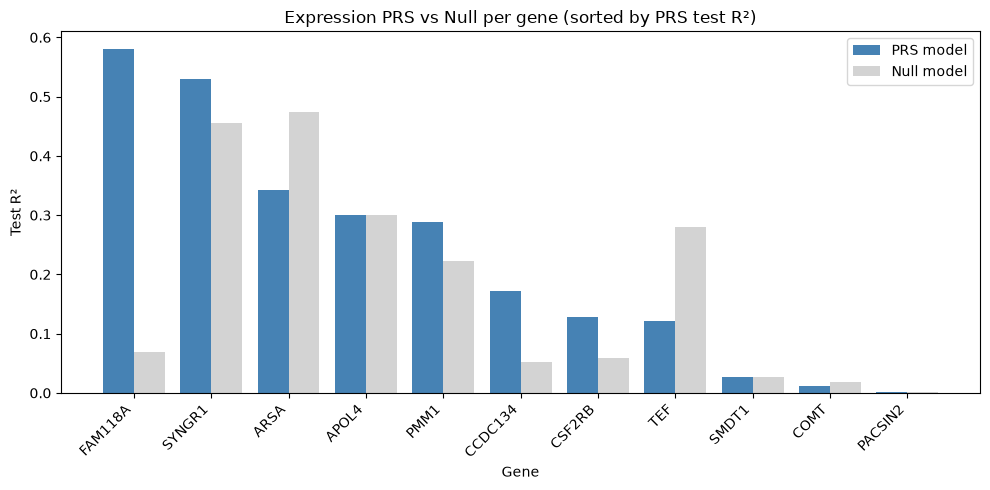

In [24]:
x = np.arange(len(cv_df))
width = 0.4
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width / 2, cv_df["test_r2"],       width, label="PRS model",  color="steelblue")
ax.bar(x + width / 2, cv_df["null_test_r2"],  width, label="Null model", color="lightgray")
ax.set_xticks(x)
ax.set_xticklabels(cv_df["symbol"], rotation=45, ha="right")
ax.set(ylabel="Test R²", xlabel="Gene", title="Expression PRS vs Null per gene (sorted by PRS test R²)")
ax.legend()
fig.tight_layout()
plt.show()

**FAM118A** stands out with the strongest expression PRS (test R² ≈ 0.58 vs null 0.07) — clear signal. Several other genes (SYNGR1, PMM1, CCDC134) also beat their nulls, while a few (ARSA, TEF, COMT) do not, showing that strong cis-eQTLs don't automatically yield a useful expression PRS.

---

### Saving the results

The full cross validation summary of one row per gene with all metrics, can now be written as a CSV so it can be inspected or reported without rerunning the per-gene cross-validation loop.


In [22]:
output_path = Path("../output/expression_prs/cv_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
cv_df.to_csv(output_path, index=False)
print(f"Saved to {output_path}.")

Saved to ..\output\expression_prs\cv_results.csv.


With the cross-validation summary saved, the file can be re-loaded directly for any later comparison or report. The same pipeline scales to more genes (or to a genome-wide run) by simply extending the `test_genes` list with no changes to the logic itself.

---